In [ ]:
from google.colab import files

uploaded = files.upload()


Saving most_streamed_spotify_2025.csv to most_streamed_spotify_2025 (1).csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.decomposition import PCA

In [ ]:
# Define different SVM kernels

kernels = [
    "linear",
    "rbf",
    "poly",
    "sigmoid"
]

# Dictionary to store results

results = {}

# Train and test each SVM model

for kernel in kernels:

    print("\nKernel:", kernel)

    # Create the SVM model

    model = SVC(
        kernel=kernel,
        C=1.0,
        gamma="scale",
        degree=3
    )

    # Train the model

    model.fit(X_train_scaled, y_train)

    # Predict the test data

    y_pred = model.predict(X_test_scaled)

    # Calculate performance metrics

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    # Store the results

    results[kernel] = {
        "model": model,
        "predictions": y_pred,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    }

    # Display the results

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))



Kernel: linear
Accuracy: 0.7945
Precision: 0.8909
Recall: 0.6712
F1 Score: 0.7656

Kernel: rbf
Accuracy: 0.7877
Precision: 0.8889
Recall: 0.6575
F1 Score: 0.7559

Kernel: poly
Accuracy: 0.5959
Precision: 1.0
Recall: 0.1918
F1 Score: 0.3218

Kernel: sigmoid
Accuracy: 0.7808
Precision: 0.8154
Recall: 0.726
F1 Score: 0.7681


In [ ]:
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst Five Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset loaded successfully!

Dataset Shape:
(730, 10)

First Five Rows:


,rank,track,artist,billed_artist_count,is_collaboration,spotify_streams_total,daily_streams,daily_streams_rank,daily_stream_share_pct,wrapped_global_top10_rank
0,1,Ordinary,Alex Warren,1,False,1948570210,2333502,11,0.1198,4.0
1,2,DtMF,Bad Bunny,1,False,1912497312,3017476,3,0.1578,5.0
2,3,Golden,HUNTR/X,1,False,1759912501,2286960,14,0.1299,7.0
3,4,BAILE INoLVIDABLE,Bad Bunny,1,False,1553054400,2624716,7,0.1690,NaN
4,5,The Fate of Ophelia,Taylor Swift,1,False,1425834222,3046797,2,0.2137,NaN



Column Names:
['rank', 'track', 'artist', 'billed_artist_count', 'is_collaboration', 'spotify_streams_total', 'daily_streams', 'daily_streams_rank', 'daily_stream_share_pct', 'wrapped_global_top10_rank']


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Information:")
df.info()


Missing Values:
rank                           0
track                          0
artist                         0
billed_artist_count            0
is_collaboration               0
spotify_streams_total          0
daily_streams                  0
daily_streams_rank             0
daily_stream_share_pct         0
wrapped_global_top10_rank    727
dtype: int64

Duplicate Records:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   rank                       730 non-null    int64  
 1   track                      730 non-null    object 
 2   artist                     730 non-null    object 
 3   billed_artist_count        730 non-null    int64  
 4   is_collaboration           730 non-null    bool   
 5   spotify_streams_total      730 non-null    int64  
 6   daily_streams              730 non-null

In [ ]:
# Required columns
required_columns = [
    "daily_streams",
    "billed_artist_count",
    "is_collaboration",
    "spotify_streams_total"
]

# Check columns
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert numerical columns
numeric_columns = [
    "daily_streams",
    "billed_artist_count",
    "spotify_streams_total"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert collaboration values to 0 and 1
if df["is_collaboration"].dtype == "object":
    df["is_collaboration"] = (
        df["is_collaboration"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": 1,
            "false": 0,
            "yes": 1,
            "no": 0,
            "1": 1,
            "0": 0
        })
    )

df["is_collaboration"] = pd.to_numeric(
    df["is_collaboration"],
    errors="coerce"
)

# Remove rows missing the required values
df = df.dropna(subset=required_columns).copy()

# Retain valid binary collaboration values
df = df[df["is_collaboration"].isin([0, 1])].copy()

df["is_collaboration"] = df["is_collaboration"].astype(int)

print("Preprocessing completed!")
print("Cleaned Dataset Shape:", df.shape)

Preprocessing completed!
Cleaned Dataset Shape: (730, 10)


In [ ]:
median_streams = df["daily_streams"].median()

print("Median Daily Streams:", median_streams)

# 0 = Low Daily Streams
# 1 = High Daily Streams

df["stream_category"] = (
    df["daily_streams"] >= median_streams
).astype(int)

print("\nClass Distribution:")
print(df["stream_category"].value_counts())

print("\n0 = Low Daily Streams")
print("1 = High Daily Streams")

Median Daily Streams: 222966.0

Class Distribution:
stream_category
1    365
0    365
Name: count, dtype: int64

0 = Low Daily Streams
1 = High Daily Streams


In [ ]:
X = df[
    [
        "billed_artist_count",
        "is_collaboration",
        "spotify_streams_total"
    ]
].copy()

y = df["stream_category"].copy()

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nNumber of Features:", X.shape[1])

Input Features:


,billed_artist_count,is_collaboration,spotify_streams_total
0,1,0,1948570210
1,1,0,1912497312
2,1,0,1759912501
3,1,0,1553054400
4,1,0,1425834222



Target Variable:
0    1
1    1
2    1
3    1
4    1
Name: stream_category, dtype: int64

Number of Features: 3


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 584
Testing Samples: 146


In [ ]:
from sklearn.pipeline import Pipeline

linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])

# Train the model
linear_model.fit(X_train, y_train)

# Predict the test data
linear_pred = linear_model.predict(X_test)

# Calculate accuracy
linear_accuracy = accuracy_score(y_test, linear_pred)

print("Linear SVM Accuracy:", round(linear_accuracy, 4))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        linear_pred,
        target_names=["Low Streams", "High Streams"],
        zero_division=0
    )
)

Linear SVM Accuracy: 0.7945

Classification Report:
              precision    recall  f1-score   support

 Low Streams       0.74      0.92      0.82        73
High Streams       0.89      0.67      0.77        73

    accuracy                           0.79       146
   macro avg       0.81      0.79      0.79       146
weighted avg       0.81      0.79      0.79       146



In [ ]:
rbf_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

# Train the model
rbf_model.fit(X_train, y_train)

# Predict the test data
rbf_pred = rbf_model.predict(X_test)

# Calculate accuracy
rbf_accuracy = accuracy_score(y_test, rbf_pred)

print("RBF SVM Accuracy:", round(rbf_accuracy, 4))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        rbf_pred,
        target_names=["Low Streams", "High Streams"],
        zero_division=0
    )
)

RBF SVM Accuracy: 0.7877

Classification Report:
              precision    recall  f1-score   support

 Low Streams       0.73      0.92      0.81        73
High Streams       0.89      0.66      0.76        73

    accuracy                           0.79       146
   macro avg       0.81      0.79      0.78       146
weighted avg       0.81      0.79      0.78       146



In [ ]:
kernels = ["linear", "rbf", "poly", "sigmoid"]

results = {}

for kernel in kernels:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel=kernel,
            C=1.0,
            gamma="scale",
            degree=3
        ))
    ])

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Evaluate
    results[kernel] = {
        "model": model,
        "predictions": y_pred,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }

# Display results
comparison = pd.DataFrame(results).T[
    ["accuracy", "precision", "recall", "f1_score"]
]

print("SVM Kernel Comparison:")
display(comparison.round(4))

SVM Kernel Comparison:


,accuracy,precision,recall,f1_score
linear,0.794521,0.890909,0.671233,0.765625
rbf,0.787671,0.888889,0.657534,0.755906
poly,0.59589,1.0,0.191781,0.321839
sigmoid,0.780822,0.815385,0.726027,0.768116


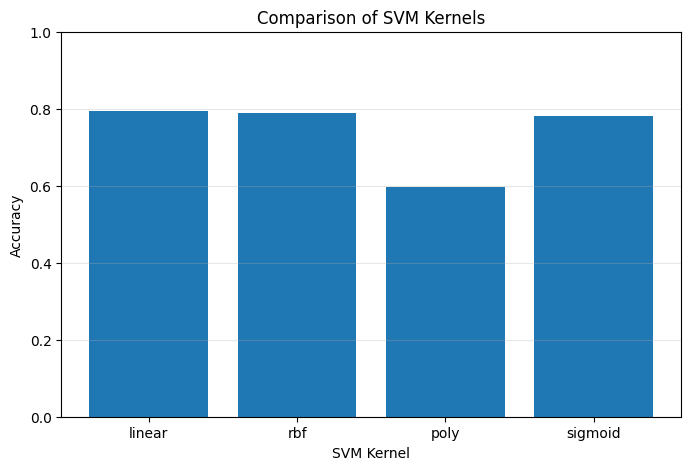

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison.index,
    comparison["accuracy"]
)

plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy")
plt.title("Comparison of SVM Kernels")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

Best Kernel: linear

Confusion Matrix:
[[67  6]
 [24 49]]


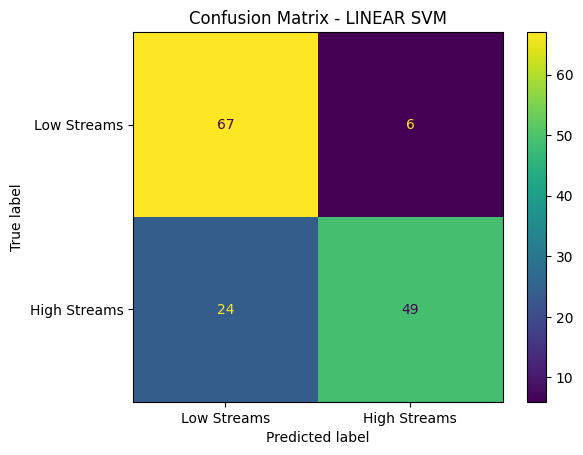

In [ ]:
best_kernel = comparison["accuracy"].idxmax()

best_model = results[best_kernel]["model"]
best_pred = results[best_kernel]["predictions"]

print("Best Kernel:", best_kernel)

cm = confusion_matrix(y_test, best_pred)

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Streams", "High Streams"]
).plot()

plt.title(f"Confusion Matrix - {best_kernel.upper()} SVM")

plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10],
        "svm__gamma": ["scale", "auto", 0.01, 0.1]
    },
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__degree": [2, 3, 4],
        "svm__gamma": ["scale", "auto"]
    }
]

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

tuned_model = grid_search.best_estimator_

tuned_pred = tuned_model.predict(X_test)

print("\nTuned Test Accuracy:")
print(round(accuracy_score(y_test, tuned_pred), 4))

Best Parameters:
{'svm__C': 10, 'svm__degree': 3, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}

Best Cross-Validation Accuracy:
0.7774

Tuned Test Accuracy:
0.7945


Original Dimensions: 3
Reduced Dimensions: 2

Explained Variance Ratio:
[0.66898357 0.33101643]

Total Variance Retained: 1.0


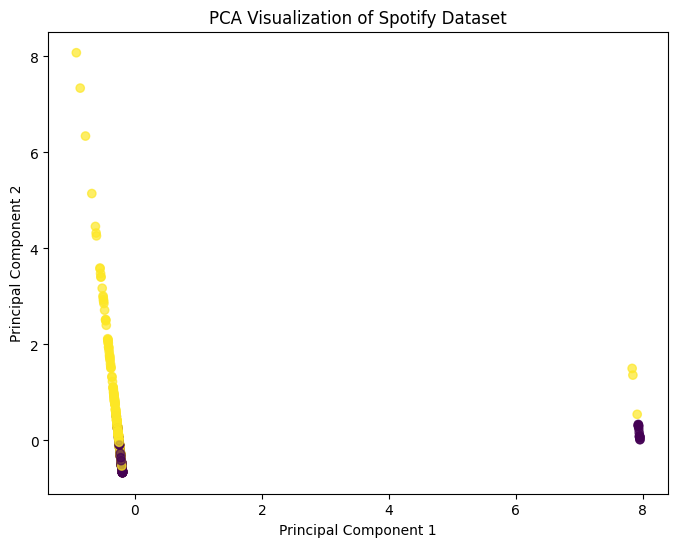

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

print("Original Dimensions:", X_train_scaled.shape[1])
print("Reduced Dimensions:", X_train_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Retained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Spotify Dataset")

plt.show()

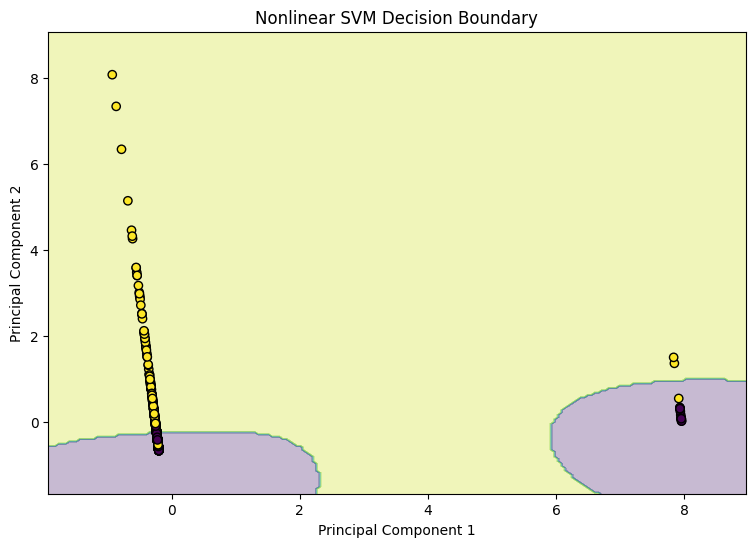

In [ ]:
visual_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

visual_model.fit(X_train_pca, y_train)

x_min = X_train_pca[:, 0].min() - 1
x_max = X_train_pca[:, 0].max() + 1

y_min = X_train_pca[:, 1].min() - 1
y_max = X_train_pca[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = visual_model.predict(grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, alpha=0.3)

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    edgecolors="black"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("Nonlinear SVM Decision Boundary")

plt.show()